# Environment Setup & Prerequisites

Olu’s first task at AfyaPlus is to prepare the tools she’ll use throughout the programme. Use this checklist to set up and verify your development environment before starting the technical lessons.

## 1. Install the required tools

- [Python 3.10 or later](https://www.python.org/downloads/) — the programming language used in the labs.
- [Visual Studio Code](https://code.visualstudio.com/) — the primary editor for code-alongs, debugging, and file management.
- [Git](https://git-scm.com/downloads) — version control for tracking changes and submitting work.
- **pip** — Python’s package manager; included with Python. You can also use Poetry or UV to manage the packages used in the project. _I'm currently using UV_
- [Ollama](https://ollama.ai/download) — local inference engine used in Tuesday’s session.

Open a terminal and check your Python version:


In [3]:
!python --version

Python 3.14.3


On macOS or Linux, use `python3 --version` if needed. Confirm the version is **3.10 or later**.

In [4]:
!python3 --version

Python was not found; run without arguments to install from the Microsoft Store, or disable this shortcut from Settings > Apps > Advanced app settings > App execution aliases.


## 2. Configure VS Code

Install these extensions:
- **Python** by Microsoft
- **Pylance**
- **Python Environment Manager**

| You can check this on the extensions manager on your VS Code Sidebar

## 3. Create the project and virtual environment

Open VS Code, then select **Terminal > New Terminal**. Run:
```bash
    # Create project directory
    mkdir afyaplus-ai-week1
    cd afyaplus-ai-week1

    # Create a virtual environment
    python -m venv venv

    # Activate the virtual environment
    # On macOS/Linux:
    source venv/bin/activate
    # On Windows:
    venv\Scripts\activate

    # Install required packages
    pip install openai httpx numpy python-dotenv
```

| You can also create these folders using the GUI (Graphic User Interface) depending on your OS (File Explorer, Finder, or whichever Linux GUI you may be using)


In [43]:
# I usually use UV for my package management, so the commands below may differ
PROJECT = "/Users/nelsonombuya/Documents/Projects/Moringa/Applied AI Engineering (Cohort 2)"
!mkdir -p "$PROJECT"
!cd "$PROJECT" && \
    ([ -f pyproject.toml ] || uv init --bare --no-readme --no-pin-python --vcs none --no-package)
!cd "$PROJECT" && uv venv .venv --allow-existing
!cd "$PROJECT" && uv sync

Using CPython 3.14.6
Creating virtual environment at: .venv
Activate with: source .venv/bin/activate
Resolved 109 packages in 23ms
Checked 105 packages in 27ms


Activate the environment:

```bash
# macOS/Linux
source venv/bin/activate

# Windows
venv\Scripts\activate
```

In [44]:
# I'll use the PROJECT variable I declared above to activate the virtual environment.
!source "$PROJECT/.venv/bin/activate"

Install the required packages:

```bash
pip install openai httpx numpy python-dotenv
```

These packages provide an OpenAI SDK, an HTTP client, numerical arrays for Monday’s labs, and support for loading environment variables.

In [45]:
# Since I'll be using uv, I can use:
!uv add openai httpx numpy python-dotenv

Resolved 109 packages in 4ms
Checked 105 packages in 3ms


## 4. Check local-model hardware

Before Tuesday’s local-model session, confirm your computer has:

- **At least 5 GB** of free SSD storage
- **At least 8 GB** of system RAM

## 5. Store your API key securely

Create an OpenAI account or sign in at [platform.openai.com](https://platform.openai.com/), then create a secret API key from **API Keys** in your account settings.

From the project folder, create a `.env` file containing your key:
Replace `sk-your-key-here` with your actual key. Never hardcode API keys in source code or commit them to Git.

In [46]:
# Skipping this command since I already have my API key in my environment variables.
# If you don't have your API key in your environment variables, you can uncomment the line below and add your OpenAI API key to a .env file.
# !echo "OPENAI_API_KEY=sk-your-key-here" > .env

Create a `.gitignore` file so sensitive files and generated files are not tracked:

In [47]:
# Skipping this command since I already have a .gitignore file in my project directory.
# If you don't have a .gitignore file in your project directory, you can uncomment the line below to create one with some common patterns to ignore.
# !printf "%s\n" ".env" "venv/" "__pycache__/" "*.pyc" > .gitignore

## 6. Verify the setup
Run these commands in the VS Code terminal (_we'll use them to test out that our initial steps were set up correctly_):

In [5]:
!python --version
!python -c "import openai, httpx, numpy, dotenv; print('All packages installed')"
!python -c "from dotenv import load_dotenv; import os; load_dotenv(); k=os.getenv('OPENAI_API_KEY'); print('OpenAI API Key loaded' if k else 'OpenAI API Key MISSING')"
!python -c "from dotenv import load_dotenv; import os; load_dotenv(); k=os.getenv('OPENROUTER_API_KEY'); print('OpenRouter API Key loaded' if k else 'OpenRouter API Key MISSING')"

Python 3.14.3
All packages installed
OpenAI API Key loaded
OpenRouter API Key loaded


Resolve any errors before moving on. Keep `.env` private, and confirm that `.gitignore` excludes it.

---

# Tokenisation
## tokenisation_lab.py

In [33]:
import numpy as np


def simple_numpy_tokenizer(text):
    # 1. Basic cleaning and splitting
    # We convert to lowercase and remove simple punctuation
    clean_text = text.lower().replace(".", "").replace("?", "")
    tokens = clean_text.split()

    # 2. Convert to NumPy array
    token_array = np.array(tokens)

    # 3. Create a vocabulary (unique tokens)
    # This represents the internal 'dictionary' our system recognises
    vocab, inverse_indices = np.unique(token_array, return_inverse=True)

    return token_array, vocab, inverse_indices


# Real patient case from the AfyaPlus portal
patient_query = "My chest hurts. Is it a heart attack?"
tokens, vocabulary, token_ids = simple_numpy_tokenizer(patient_query)

print("--- Tokenisation Results ---")
print(f"Original Text: {patient_query}")
print(f"Tokens: {tokens}")
print(f"Vocabulary: {vocabulary}")
print(f"Token IDs (Numerical Representation): {token_ids}")

--- Tokenisation Results ---
Original Text: My chest hurts. Is it a heart attack?
Tokens: ['my' 'chest' 'hurts' 'is' 'it' 'a' 'heart' 'attack']
Vocabulary: ['a' 'attack' 'chest' 'heart' 'hurts' 'is' 'it' 'my']
Token IDs (Numerical Representation): [7 2 4 5 6 0 3 1]


## challenge1_tokeniser.py (starter)

In [ ]:
import numpy as np


def emergency_tokeniser(text):
    """Split text into tokens while preserving '!' as separate tokens."""
    text = text.lower()
    # TODO 1: Pad '!' with spaces so split() treats them as separate tokens.
    text = text.replace("!", " ! ")

    # TODO 2: Remove any other punctuation that should not be a token.
    text = (
        text.replace(".", "")
        .replace(",", "")
        .replace("?", "")
        .replace(";", "")
        .replace(":", "")
        .replace('"', "")
        .replace("'", "")
    )

    # TODO 3: Split on whitespace and return a NumPy array.
    tokens = np.array(text.split())  # replace this with the real result
    return tokens


# Test cases
samples = [
    "Help!!!",
    "I cannot breathe!",
    "My chest hurts.",
    "My chest hurts. Is it a heart attack?",
    "My chest hurts!!!",
]
for s in samples:
    tokens = emergency_tokeniser(s)
    line = f"{s} -> {tokens}"
    width = max(len(f"{sample} -> {emergency_tokeniser(sample)}") for sample in samples)
    print(f"{line:<{width}} | count: {len(tokens)}")

Help!!! -> ['help' '!' '!' '!']                                                                | count: 4
I cannot breathe! -> ['i' 'cannot' 'breathe' '!']                                              | count: 4
My chest hurts. -> ['my' 'chest' 'hurts']                                                      | count: 3
My chest hurts. Is it a heart attack? -> ['my' 'chest' 'hurts' 'is' 'it' 'a' 'heart' 'attack'] | count: 8
My chest hurts!!! -> ['my' 'chest' 'hurts' '!' '!' '!']                                        | count: 6


# Embeddings
## embeddings_lab.py

In [14]:
import numpy as np

# Simulated 3D word embeddings.
# Each dimension represents: [Clinical-Symptom, Administrative, Time/Urgency]
embeddings = {
    "fever": np.array([0.9, 0.0, 0.3]),
    "pain": np.array([0.8, 0.1, 0.4]),
    "discharge": np.array([0.5, 0.5, 0.1]),  # Ambiguous word!
    "billing": np.array([0.0, 0.9, 0.1]),
    "admit": np.array([0.2, 0.8, 0.2]),
}


def cosine_similarity(word1, word2):
    """Calculate how close two words are in embedding space."""
    vec1 = embeddings[word1]
    vec2 = embeddings[word2]
    return np.dot(vec1, vec2) / (np.linalg.norm(vec1) * np.linalg.norm(vec2))


# If 'discharge' appears alongside 'pain', it is likely a clinical symptom.
# If it appears alongside 'billing', it is administrative.
print("--- Context-Disambiguation via Cosine Similarity ---")
print(f"Context Match (Discharge + Pain): {cosine_similarity('discharge', 'pain'):.4f}")
print(
    f"Context Match (Discharge + Billing): {cosine_similarity('discharge', 'billing'):.4f}"
)

--- Context-Disambiguation via Cosine Similarity ---
Context Match (Discharge + Pain): 0.7624
Context Match (Discharge + Billing): 0.7113


## challenge2_embeddings.py (starter)

In [ ]:
import numpy as np

embeddings = {
    "fever": np.array([0.9, 0.0, 0.3]),
    "pain": np.array([0.8, 0.1, 0.4]),
    "discharge": np.array([0.5, 0.5, 0.1]),
    "billing": np.array([0.0, 0.9, 0.1]),
    "admit": np.array([0.2, 0.8, 0.2]),
    # TODO 1: Add a 'cough' vector that sits close to 'fever' and far from 'billing'.
    "cough": np.array([0.85, 0.05, 0.25]),
}


def cosine_similarity(word1, word2):
    vec1, vec2 = embeddings[word1], embeddings[word2]
    return np.dot(vec1, vec2) / (np.linalg.norm(vec1) * np.linalg.norm(vec2))


# TODO 2: Print cosine_similarity('cough', 'fever') and cosine_similarity('cough', 'billing').
cough_fever_similarity = cosine_similarity("cough", "fever")
print(f"Context Match (Cough + Fever): {cough_fever_similarity:.4f}")

cough_billing_similarity = cosine_similarity("cough", "billing")
print(f"Context Match (Cough + Billing): {cough_billing_similarity:.4f}")

# TODO 3: Confirm the fever score is meaningfully higher than the billing score.
print(
    "Is fever score higher than Billing score? "
    f"{cough_fever_similarity > cough_billing_similarity}"
)

Context Match (Cough + Fever): 0.9978
Context Match (Cough + Billing): 0.0871
Is fever score higher than Billing score? True


# Prediction and Temperature
## prediction_lab.py

In [37]:
import numpy as np


def predict_next_token(context, temperature=1.0):
    """
    Simulate how an LLM predicts the next token.
    Lower temperature = more predictable (safer for medical advice).
    Higher temperature = more creative (good for greetings).
    """
    predictions = {
        "patient has fever": {
            "and": 0.3,
            "with": 0.25,
            "recommend": 0.2,
            "suggesting": 0.15,
            "indicating": 0.1,
        }
    }
    if context not in predictions:
        return "[unknown context]"

    probs = predictions[context]
    tokens = list(probs.keys())
    weights = np.array(list(probs.values()))

    # Apply temperature scaling
    scaled = weights ** (1.0 / temperature)
    scaled = scaled / scaled.sum()
    print(f"Tokens: {tokens}")
    print(f"Scaled weights (temperature={temperature}): {scaled}")
    print(f"Normalized probabilities: {scaled}")

    chosen = np.random.choice(tokens, p=scaled)
    return chosen


print("--- Token Prediction Simulation ---")
print("\nLow temperature (0.3) - Conservative/Safe:")
for i in range(3):
    token = predict_next_token("patient has fever", temperature=0.3)
    print(f"  Attempt {i+1}: '{token}'")

print("\nHigh temperature (2.0) - Creative/Varied:")
for i in range(3):
    token = predict_next_token("patient has fever", temperature=2.0)
    print(f"  Attempt {i+1}: '{token}'")

--- Token Prediction Simulation ---

Low temperature (0.3) - Conservative/Safe:
Tokens: ['and', 'with', 'recommend', 'suggesting', 'indicating']
Scaled weights (temperature=0.3): [0.5185882  0.2824133  0.13423067 0.05145047 0.01331737]
Normalized probabilities: [0.5185882  0.2824133  0.13423067 0.05145047 0.01331737]
  Attempt 1: 'and'
Tokens: ['and', 'with', 'recommend', 'suggesting', 'indicating']
Scaled weights (temperature=0.3): [0.5185882  0.2824133  0.13423067 0.05145047 0.01331737]
Normalized probabilities: [0.5185882  0.2824133  0.13423067 0.05145047 0.01331737]
  Attempt 2: 'with'
Tokens: ['and', 'with', 'recommend', 'suggesting', 'indicating']
Scaled weights (temperature=0.3): [0.5185882  0.2824133  0.13423067 0.05145047 0.01331737]
Normalized probabilities: [0.5185882  0.2824133  0.13423067 0.05145047 0.01331737]
  Attempt 3: 'with'

High temperature (2.0) - Creative/Varied:
Tokens: ['and', 'with', 'recommend', 'suggesting', 'indicating']
Scaled weights (temperature=2.0): [0

## temp_experiment.py (starter)

In [38]:
import numpy as np
from collections import Counter


def predict_next_token(context, temperature=1.0):
    probs = {
        "and": 0.3,
        "with": 0.25,
        "recommend": 0.2,
        "suggesting": 0.15,
        "indicating": 0.1,
    }
    tokens = list(probs.keys())
    weights = np.array(list(probs.values()))
    scaled = weights ** (1.0 / temperature)
    scaled = scaled / scaled.sum()
    return np.random.choice(tokens, p=scaled)


temperatures = [0.1, 0.5, 1.0, 2.0]
num_trials = 10
# TODO: For each temperature, run num_trials predictions
# and count how often each token is selected.
print("--- Temperature Experiment Results ---")
for temp in temperatures:
    results = [predict_next_token("patient has fever", temp) for _ in range(num_trials)]
    counts = Counter(results)
    top_token, top_count = counts.most_common(1)[0]
    print(
        f"Temp {temp:.1f}: top token = '{top_token}' ({top_count}/{num_trials}); "
        f"unique tokens seen = {len(counts)}"
    )
print("\nRecommendation for AfyaPlus:")
print("  Symptom triage:        temp=0.1-0.3 (consistent, safe responses)")
print("  Greetings:             temp=0.7-1.0 (natural variety)")
print("  Appointment reminders: temp=0.2-0.4 (accurate but slightly varied)")

--- Temperature Experiment Results ---
Temp 0.1: top token = 'and' (7/10); unique tokens seen = 3
Temp 0.5: top token = 'and' (6/10); unique tokens seen = 4
Temp 1.0: top token = 'with' (3/10); unique tokens seen = 5
Temp 2.0: top token = 'with' (4/10); unique tokens seen = 5

Recommendation for AfyaPlus:
  Symptom triage:        temp=0.1-0.3 (consistent, safe responses)
  Greetings:             temp=0.7-1.0 (natural variety)
  Appointment reminders: temp=0.2-0.4 (accurate but slightly varied)


# What LLMs **can** and **cannot** do
## break_the_model.py (template)

In [ ]:
# We will run this script during Tuesday's Lab 5 (first OpenAI call).
# For now, capture the prompt and predict the model's behaviour.

PROMPT = "What is AfyaPlus Health's official malaria treatment policy for 2027?"

# TODO 1: Note what answer YOU expect the model to give (no policy exists yet).
# Since the model has no knowledge of a specific policy for 2027, it may either:
#   - Invent a confident-sounding policy.
#   - State that it does not have information about the specific policy for 2027.

# TODO 2: Once Tuesday's lab is set up, send PROMPT through the OpenAI client.
# * I ran the prompt through Perplexity AI and it returned the follow:
# I couldn’t verify an **official** malaria treatment policy issued by AfyaPlus Health
# for 2027. My searches did not locate an AfyaPlus-authored policy document or
# announcement, so I shouldn’t attribute a treatment regimen to the organisation.
# What I could verify
# Kenya’s Ministry of Health has published the Kenya Malaria Policy, Second Edition
# (April 2024), and the Kenya Malaria Strategy 2023–2027. These are national documents—not
# evidence of AfyaPlus Health’s own policy or its adoption of specific protocols for 2027.
# [afro.who]
# (https://www.afro.who.int/sites/default/files/2025-03/National%20Malaria%20Policy%202024.pdf)
# To establish AfyaPlus Health’s policy, I’d need its published clinical guideline, an
# approved internal policy, or an official statement specifying the version and effective
# date. As of October 15, 2026, 2027 is still upcoming; I can’t establish whether such a
# policy has already been approved or will be issued later.
# Can you share AfyaPlus Health’s website or the document where this policy is mentioned?

# TODO 3: Document whether the model invented a confident-sounding policy.
# The model did not invent a confident-sounding policy. Instead, it correctly stated that
# it could not verify an official malaria treatment policy issued by AfyaPlus Health for
# 2027 and provided context about the national malaria policy in Kenya.

# Monday Further Challenges
## The Cost vs Care Triage System
### cost_vs_care.py
Your manager at AfyaPlus is worried about API costs. Rural users often send messages in a mix of Swahili and English, which increases token counts. You need to prove that ‘summarising’ the query before sending it to the expensive ‘Expert Model’ saves money.

In [40]:
import numpy as np


def simple_numpy_tokenizer(text):
    clean_text = text.lower().replace(".", "").replace("?", "").replace(",", "")
    tokens = clean_text.split()
    return np.array(tokens)


original_query = (
    "Hujambo, it is Juma. I am feeling very hot, my head hurts since yesterday, "
    "and I am coughing. I cannot go to the clinic because of the rain. What should I do?"
)

# TODO 1: Tokenise the original_query and count the tokens.
original_tokens = simple_numpy_tokenizer(original_query)
print(f"Original Query Tokens: {original_tokens}")

original_token_count = len(original_tokens)
print(f"Original Query Token Count: {original_token_count}")

# TODO 2: Manually rewrite the query as a 10-word summary of the medical facts only.
summary = "I am feeling very hot, my head hurts, and I am coughing."

# TODO 3: Tokenise the summary and count the tokens.
summary_tokens = simple_numpy_tokenizer(summary)
print(f"Summary Tokens: {summary_tokens}")

summary_token_count = len(summary_tokens)
print(f"Summary Token Count: {summary_token_count}")

# TODO 4: Calculate the percentage of tokens saved.
tokens_saved = original_token_count - summary_token_count
print(f"Tokens Saved: {tokens_saved}")

percentage_saved = (tokens_saved / original_token_count) * 100
print(f"Percentage of Tokens Saved: {percentage_saved:.2f}%")

# TODO 5: If 1,000 users send this query daily, how many tokens are saved per month?
daily_users = 1_000_000
tokens_saved_per_day = tokens_saved * daily_users
print(f"Tokens Saved Per Day: {tokens_saved_per_day}")

tokens_saved_per_month = tokens_saved_per_day * 30
print(f"Tokens Saved Per Month: {tokens_saved_per_month}")

Original Query Tokens: ['hujambo' 'it' 'is' 'juma' 'i' 'am' 'feeling' 'very' 'hot' 'my' 'head'
 'hurts' 'since' 'yesterday' 'and' 'i' 'am' 'coughing' 'i' 'cannot' 'go'
 'to' 'the' 'clinic' 'because' 'of' 'the' 'rain' 'what' 'should' 'i' 'do']
Original Query Token Count: 32
Summary Tokens: ['i' 'am' 'feeling' 'very' 'hot' 'my' 'head' 'hurts' 'and' 'i' 'am'
 'coughing']
Summary Token Count: 12
Tokens Saved: 20
Percentage of Tokens Saved: 62.50%
Tokens Saved Per Day: 20000000
Tokens Saved Per Month: 600000000


### Draw the Data Journey
A patient types ‘My head hurts’ into the AfyaPlus web chat. Draw a diagram showing how that message travels through the system, including the five boxes from Guided Exercise 2.

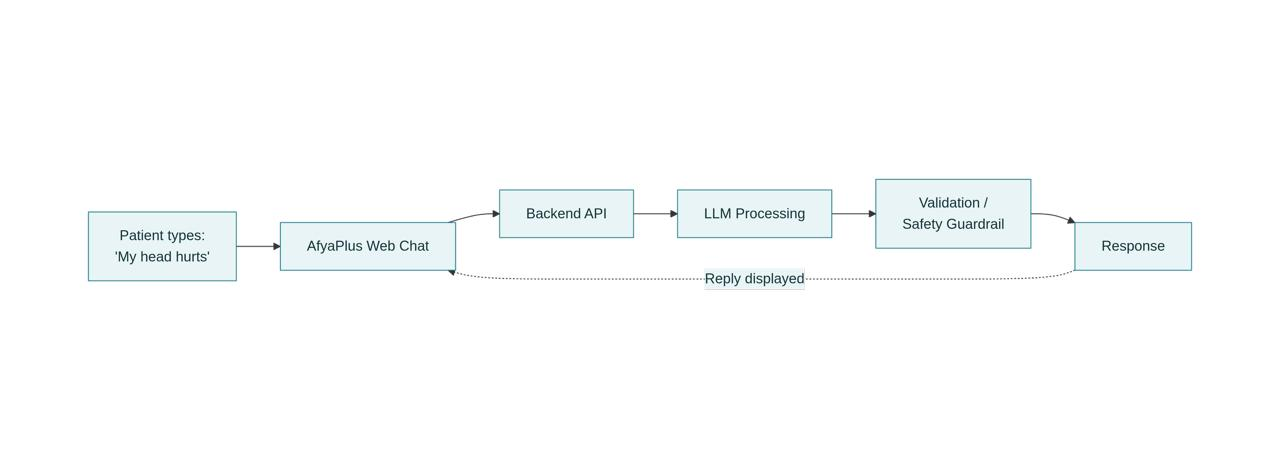

### Explain Hallucination to a Non-Technical Friend
Write a short paragraph (3 to 4 sentences) explaining what hallucination is to a friend who does not work in tech. Use an analogy that anyone can grasp.

In [ ]:
# Hallucination is if an AI says something untrue as if it were a fact.
# Imagine a friend who's great at answering questions and telling stories.
# But when they don't know the answer, instead of saying "I'm not sure,"
# they make up something that sounds believable, with lots of convincing details,
# without realizing they're wrong.

# The AI isn't lying, but instead filling in gaps in what it knows with something that
# sounds right based on patterns it has learned, even if it is not true.

### Fix the Code: The Tokeniser That Loses Punctuation
Symptom: The system needs to flag '!' as its own urgency token, but the output is ['help', 'i', 'cannot', 'breathe'] with every '!' gone.

Run this broken version, read the error, then diagnose it:
```python
import numpy as np

def urgency_tokeniser(text):
    text = text.lower()
    text = text.replace("!", "")      # bug is on this line
    tokens = np.array(text.split())
    return tokens

print(urgency_tokeniser("Help!!! I cannot breathe!"))
```

Which single change makes '!' survive as its own token?

A.Use text.split("!")
B.Wrap the result in list() not np.array()
C.Remove the .lower() call
D.Replace "!" with " ! " instead of ""

In [42]:
import numpy as np


def urgency_tokeniser(text):
    text = text.lower()
    text = text.replace("!", " ! ")  # bug is on this line
    tokens = np.array(text.split())
    return tokens


print(urgency_tokeniser("Help!!! I cannot breathe!"))

['help' '!' '!' '!' 'i' 'cannot' 'breathe' '!']
